# Day 13-14: SVM Hands-On Industry Applications

This notebook applies Support Vector Machines to the 12 provided industry datasets. Ten datasets have classification targets; construction strength and energy consumption are continuous, so those use Support Vector Regression (SVR). Numerical predictors are scaled and categorical predictors are one-hot encoded inside each training pipeline. A linear and an RBF model are compared on held-out data.

## 1. Load the task definitions

The product identifier in supply chain is excluded as a predictor. Target columns follow the supplied industry problem statements. For manageable kernel training, each training split is sampled to at most 2,500 rows; held-out test rows remain untouched.

## 1. Load the task definitions

Use the provided data fields to define the classification or regression target for each industry.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC,SVR
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,r2_score,mean_absolute_error

TASKS={
'Supply Chain':('supply_chain_dataset.csv',['region','warehouse','category','price','discount_percent','inventory_level','lead_time_days','daily_sales','seasonality_index'],'stockout_risk','classification'),
'BFSI Fraud':('bfsi_fraud_dataset.csv',['transaction_amount','transaction_hour','transaction_type','device_type','location','failed_login_attempts','transactions_last_24h','account_age_days'],'is_fraud','classification'),
'AdTech Conversion':('adtech_ecommerce_dataset.csv',['session_duration_sec','pages_viewed','clicks','ad_impressions','device_type','traffic_source','cart_additions','past_purchases'],'conversion','classification'),
'Telecom Churn':('telecom_churn_dataset.csv',['monthly_data_usage_gb','call_minutes','monthly_bill','complaints_last_6m','tenure_months','plan_type','region','support_calls'],'churn','classification'),
'Cybersecurity':('cybersecurity_dataset.csv',['connection_duration_sec','packet_size','failed_logins','source_port','destination_port','packets_transferred','protocol'],'intrusion_flag','classification'),
'IT Infrastructure':('it_infrastructure_dataset.csv',['cpu_usage_percent','memory_usage_percent','disk_io','network_latency_ms','active_processes','server_type'],'system_failure_risk','classification'),
'Healthcare':('healthcare_dataset.csv',['age','bmi','blood_pressure','glucose_level','cholesterol','heart_rate','physical_activity_score'],'disease_risk','classification'),
'HR Attrition':('hr_analytics_dataset.csv',['age','salary','years_at_company','performance_score','overtime_hours','employee_satisfaction','job_role','department'],'attrition_risk','classification'),
'Construction Strength':('construction_dataset.csv',['cement','fly_ash','water','superplasticizer','coarse_aggregate','fine_aggregate','curing_days'],'compressive_strength','regression'),
'Energy Consumption':('energy_utilities_dataset.csv',['temperature_c','humidity_percent','wind_speed','consumer_type','season','appliance_usage_hours'],'energy_consumption_kwh','regression'),
'EdTech Performance':('edtech_dataset.csv',['study_hours_per_week','attendance_percent','assignments_completed','quiz_score','forum_interactions','course_name'],'performance_level','classification'),
'Automotive Risk':('automotive_adas_dataset.csv',['speed_kmph','braking_intensity','lane_deviation','reaction_time_sec','acceleration','road_type','weather_condition'],'driving_risk','classification')}
roots=[Path('../Hands ON -20261023T181134Z-1-001/Hands ON'),Path('Hands ON -20261023T181134Z-1-001/Hands ON'),Path('Assignment Day-13-14/Hands ON -20261023T181134Z-1-001/Hands ON')]
DATA_ROOT=next((p for p in roots if p.exists()),None)
if DATA_ROOT is None:raise FileNotFoundError('Could not locate the Hands ON data folder.')
print('Dataset folder:',DATA_ROOT.resolve())
print('Industry tasks:',len(TASKS))

Dataset folder: C:\Users\hp\Assignments-Day-3\Assignment Day-13-14\Hands ON -20261023T181134Z-1-001\Hands ON
Industry tasks: 12


## 2. Fit and evaluate

The preprocessing and SVM are kept together in a pipeline so scaling and category encoding are learned from training data only. A 20% stratified holdout is used for classification.

In [2]:
rows=[];models={};test_data={}
for task,(filename,features,target,kind) in TASKS.items():
    df=pd.read_csv(DATA_ROOT/filename)
    X=df[features].copy();y=df[target].copy()
    if df[features+[target]].isna().any().any():raise ValueError(f'{task}: missing values need handling.')
    X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=42,stratify=y if kind=='classification' else None)
    n=min(2500,len(X_train))
    sampled=X_train.sample(n=n,random_state=42)
    ys=y_train.loc[sampled.index]
    cat=[c for c in features if X[c].dtype=='object']
    num=[c for c in features if c not in cat]
    prep=ColumnTransformer([('num',StandardScaler(),num),('cat',OneHotEncoder(handle_unknown='ignore'),cat)])
    if kind=='classification':
        for name,est in [('Linear SVM',SVC(kernel='linear',C=1,class_weight='balanced')),('RBF SVM',SVC(kernel='rbf',C=1,gamma='scale',class_weight='balanced'))]:
            pipe=Pipeline([('prep',prep),('svm',est)])
            pipe.fit(sampled,ys);pred=pipe.predict(X_test)
            rows.append({'Industry':task,'Model':name,'Target':target,'Train rows':n,'Test rows':len(X_test),'Accuracy':accuracy_score(y_test,pred),'Precision macro':precision_score(y_test,pred,average='macro',zero_division=0),'Recall macro':recall_score(y_test,pred,average='macro',zero_division=0),'F1 macro':f1_score(y_test,pred,average='macro',zero_division=0)})
            models[(task,name)]=pipe
            if name=='RBF SVM':test_data[task]=(y_test,pred)
    else:
        for name,est in [('Linear SVR',SVR(kernel='linear',C=10)),('RBF SVR',SVR(kernel='rbf',C=10,gamma='scale'))]:
            pipe=Pipeline([('prep',prep),('svm',est)])
            pipe.fit(sampled,ys);pred=pipe.predict(X_test)
            rows.append({'Industry':task,'Model':name,'Target':target,'Train rows':n,'Test rows':len(X_test),'R2':r2_score(y_test,pred),'MAE':mean_absolute_error(y_test,pred)})
            models[(task,name)]=pipe
results=pd.DataFrame(rows)
print(results.round(3).to_string(index=False))

             Industry      Model                 Target  Train rows  Test rows  Accuracy  Precision macro  Recall macro  F1 macro    R2   MAE
         Supply Chain Linear SVM          stockout_risk        2500       2000     1.000            1.000         1.000     1.000   NaN   NaN
         Supply Chain    RBF SVM          stockout_risk        2500       2000     1.000            1.000         1.000     1.000   NaN   NaN
           BFSI Fraud Linear SVM               is_fraud        2500       2000     0.908            0.820         0.921     0.857   NaN   NaN
           BFSI Fraud    RBF SVM               is_fraud        2500       2000     0.955            0.896         0.962     0.924   NaN   NaN
    AdTech Conversion Linear SVM             conversion        2500       2000     0.792            0.773         0.803     0.779   NaN   NaN
    AdTech Conversion    RBF SVM             conversion        2500       2000     0.938            0.921         0.950     0.932   NaN   NaN
      

Regression R-squared:
Model                  Linear SVR  RBF SVR
Industry                                  
Construction Strength       0.851    0.832
Energy Consumption          0.941    0.933


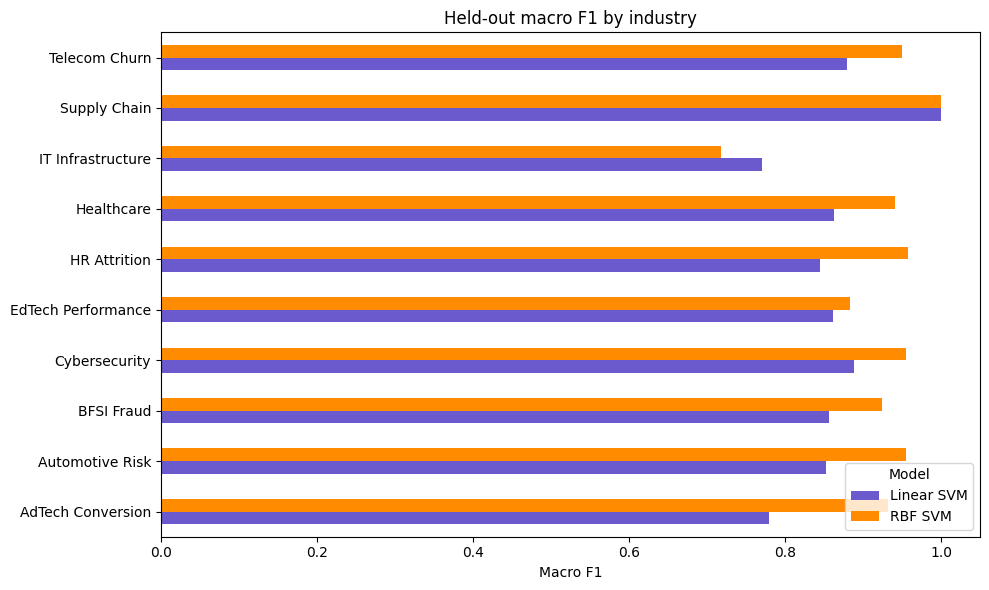

In [3]:
classification=results[results['Accuracy'].notna()].pivot(index='Industry',columns='Model',values='F1 macro')
ax=classification.plot(kind='barh',figsize=(10,6),color=['slateblue','darkorange'])
ax.set(title='Held-out macro F1 by industry',xlabel='Macro F1',ylabel='')
plt.tight_layout();plt.show()
regression=results[results['R2'].notna()].pivot(index='Industry',columns='Model',values='R2')
print('Regression R-squared:')
print(regression.round(3).to_string())

## 2. Interpret the results

Use macro precision, recall, and F1 to compare classes fairly, especially when one label is rare. For regression, compare R-squared and MAE within each target's units. Linear SVMs are compact baselines; RBF models can capture curved boundaries but depend on scaling and may cost more at prediction. These scores are baselines on the supplied data, not deployment guarantees. For production use, tune C and kernel settings with cross-validation and check class-specific errors, data drift, and probability calibration where needed.